
<div class="alert alert-info" style="background-color:#001b79; color:white; padding:0px 10px; border-radius:5px;"><h2 style='margin:10px 5px'> Logistic Regression </h2>
</div>

###  Logistic Regression 			

- Logistic regression are S-curve/Sigmoid-Curve	

- Logistic Regression is stastical method to predict binary outcome. The target variable is binary and independent varibles are continous.	

- Independent variables(X-axis) are continues, here depenent variables (Y-axis) are discret 0 or 1, based on threshold level, above that will be treated as 1 below as 0	

- In Linear Regression output values also continues, but in Logistic regression output values are  binary values	


<div class="alert alert-info" style="background-color:#001b32; color:white; padding:0px 10px; border-radius:5px;"><h2 style='margin:10px 5px'>Problem  Statement </h2>
</div>


# CANCER DETECTION

## Business challenge/requirement
    John Cancer Hospital (JCH) is a leading cancer hospital in USA. 
    It specializes in preventingbreast cancer. 
    Over the period of the last few years, JCH has collected breast cancer data from patients who came for screening/treatment.
    
    However,this data has almost 30 attributes and is difficult to run and interpret the result. 
    You as ML expert has to reduce the no. of attributes (Dimensionality Reduction) so that results are meaningful and accurate.
    
    Key issues
        Reduce the no. of attributes/features in data to make the results and analysis comprehensible by doctors
        
     Business benefits
         Improved success rate of cancer detection and hence direct impact on revenue and profit of hospital. More than that it contributes to JCH's mission "Better Life"

# CANCER DETECTION

>  We have 2 different cells 1. M - Malignant(Cancerous) 2. B - Benignant (Not Cancerous)

> Early detection increases the survival chances by almost 99%. 

> "diagnosisis" the output column, here we are going to predict weather its cancerous data or not.

> For this problem we can use below all ML algorithms and other algorithms, but Logistic Regression is the best algorithm, because it implies "Probability interpretaion"

    > Naive Bayes
    > Logistic Regression
    > Support Vector Machine(SVM)
    > Decision Tree
    > Reinforcement Learning
    > Neural Network
    > K nearest Neighbour(KNN)
    
 > Reason For Logistic Regression
 
     > Probability Interpreatition     
             Probability Interpretation is easy but its not there in Decision Tree and SVM classifier
             
     > Feature Correlation     
             In Logistic Regression we no need to worry about feature being Correated unlike Naive Bayes
             
     > Upgrade:      
             The model can be easily upgraded to take in new data. This can be done using online Gradient Descent
         
     > Adjustment:     
             Logistic Regression Model helps to easily adjust Classification Thresholds when we are unsure about the confidence interval
             
     > Computational Considerations:     
             LR models are ussually Computationally less complicated to build and require less Computational time to train compared with ANN
         

## Objective

 > The aim of this analysis is to use Logistic Regression to classify the data into two classes of diagnosis— Malignant & Benign. 
    
  > The evaluation metrics used are accuracy, ROC, confusion matrix, precision-recall.
  
  
  > Class distribution: 357 benign, 212 malignant
  
  > Number of instances: 569; Number of attributes: 32

# Logistic Regression

#  1. Import all Librariy

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [26]:
# load the data
data = pd.read_csv('../Dataset/cancer_data.csv')
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 2. Data Exploration with Graphs and Visualization

In [27]:
# data wrangling- Remove unncessory columns
data.drop(['id', 'Unnamed: 32'], axis=1, inplace=True)
data.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [28]:
# Impute the only categorical column
data["diagnosis"].replace(to_replace = dict(M = 1, B = 0), inplace = True)
# OR
#data['diagnosis'] = data['diagnosis'].replace(['M','B'],[1,0])
data.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [29]:
print(data.isnull().sum())
#No missing data

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


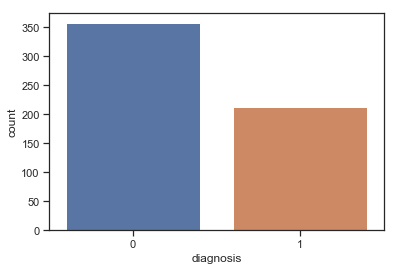

In [30]:
# visulize the o/p gives count
sns.countplot(data['diagnosis'], label='count')
# By this we can see more are Balignant not cancerous comapred to cancerous patient

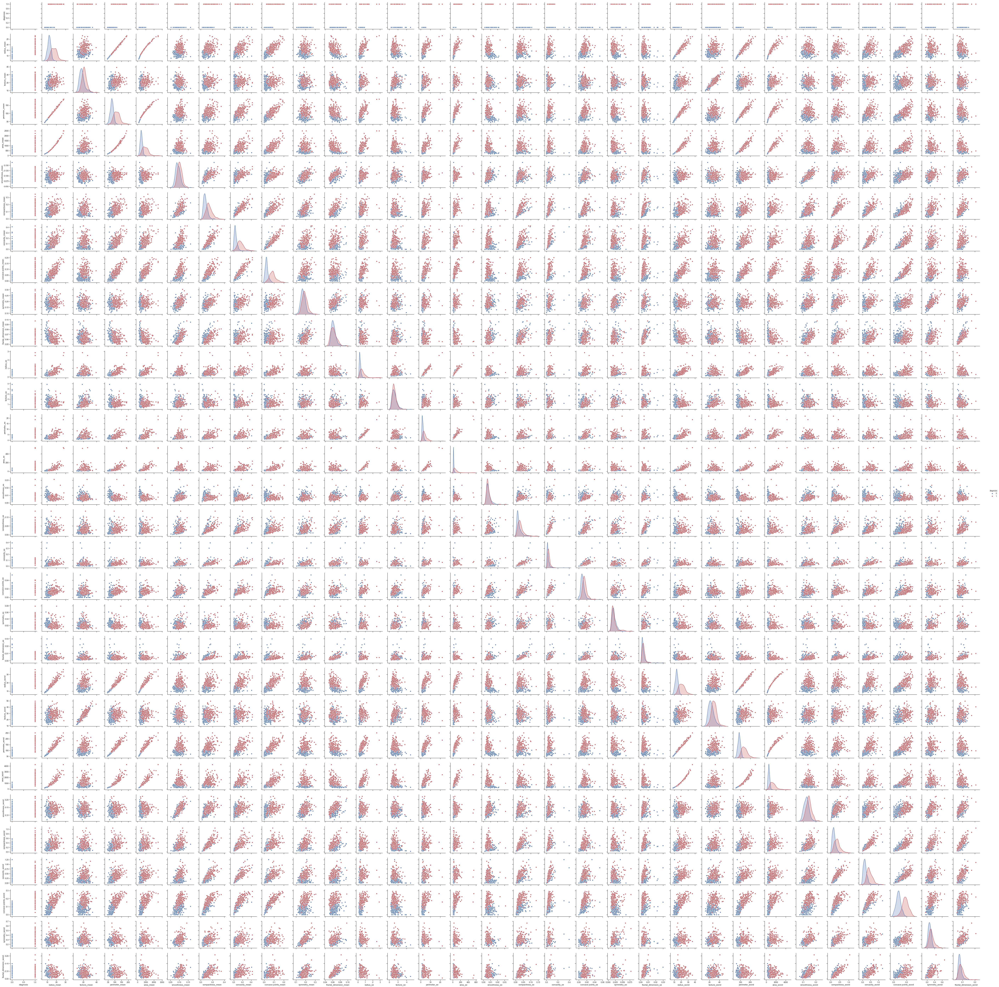

In [31]:
#Visualization Per Pair
sns.set(style="ticks", color_codes=True)
# Here it producs color code blue and red for diagnosis value M and B
g = sns.pairplot(data, palette = ('b', 'r'), hue="diagnosis", height=2.5)
plt.show()

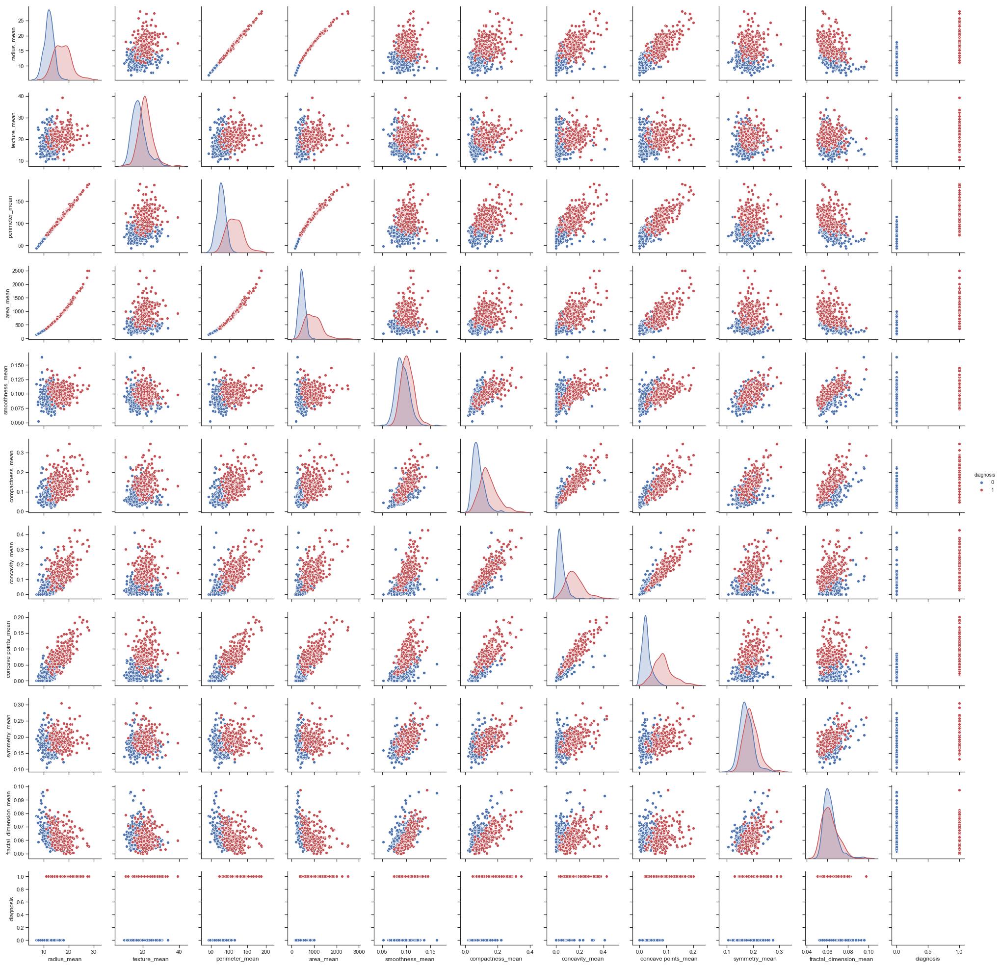

In [32]:
#Do pair plot with selected colums for better understanding
Column = ['radius_mean','texture_mean', 'perimeter_mean',
                  'area_mean','smoothness_mean','compactness_mean',
                  'concavity_mean', 'concave points_mean', 'symmetry_mean',
                 'fractal_dimension_mean','diagnosis']
data1 = data[Column]
#Visualization Per Pair
sns.set(style="ticks", color_codes=True)
# Here it producs color code blue and red for diagnosis value M and B
g = sns.pairplot(data1, palette = ('b', 'r'), hue="diagnosis", height=2.5)
plt.show()

In [33]:
# Some of these pairs, like Radius vs. Texture or Perimeter vs. Smoothness, have a right separation level concerning the Diagnosis (blue points = Benign; red spots = Malignant). 
# Visualizing features in plots of pairs represent an excellent tool, primarily because of its immediacy.

                         diagnosis  radius_mean  texture_mean  perimeter_mean  \
diagnosis                 1.000000     0.730029      0.415185        0.742636   
radius_mean               0.730029     1.000000      0.323782        0.997855   
texture_mean              0.415185     0.323782      1.000000        0.329533   
perimeter_mean            0.742636     0.997855      0.329533        1.000000   
area_mean                 0.708984     0.987357      0.321086        0.986507   
smoothness_mean           0.358560     0.170581     -0.023389        0.207278   
compactness_mean          0.596534     0.506124      0.236702        0.556936   
concavity_mean            0.696360     0.676764      0.302418        0.716136   
concave points_mean       0.776614     0.822529      0.293464        0.850977   
symmetry_mean             0.330499     0.147741      0.071401        0.183027   
fractal_dimension_mean   -0.012838    -0.311631     -0.076437       -0.261477   
radius_se                 0.

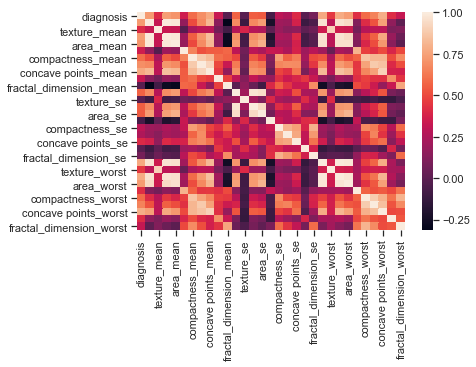

In [34]:
# With Heat map also we can decide which are correlated more and we can ignore repeatative type

corr = data.corr()
print(corr)
#plt.figure(figsize=(5,10))
sns.heatmap(corr)
plt.show()

In [35]:
#
"""From above heat map we can conclude that we can take only mean of only below fields ['radius_mean','texture_mean', 'perimeter_mean',
                  'area_mean','smoothness_mean','compactness_mean',
                  'concavity_mean', 'concave points_mean', 'symmetry_mean',
                 'fractal_dimension_mean']
                 
                 Remaings are either highly positive correlated or highly negative correlated
                 """

"From above heat map we can conclude that we can take only mean of only below fields ['radius_mean','texture_mean', 'perimeter_mean',\n                  'area_mean','smoothness_mean','compactness_mean',\n                  'concavity_mean', 'concave points_mean', 'symmetry_mean',\n                 'fractal_dimension_mean']\n                 \n                 Remaings are either highly positive correlated or highly negative correlated\n                 "

In [36]:
# https://towardsdatascience.com/logistic-regression-for-malignancy-prediction-in-cancer-27b1a1960184
#In above link we have function to see which are having absolute correlation >0.90 
# and makes that as drop list and drops those column from main datset

# 3. Building Machine Learning Logistic Models

In [37]:
# split the data into training and testing
train, test = train_test_split(data, test_size=0.3)

In [38]:
train.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
274,1,17.93,24.48,115.20,998.9,0.08855,0.07027,0.05699,0.04744,0.1538,...,20.92,34.69,135.1,1320.0,0.1315,0.1806,0.2080,0.1136,0.2504,0.07948
65,1,14.78,23.94,97.40,668.3,0.11720,0.14790,0.12670,0.09029,0.1953,...,17.31,33.39,114.6,925.1,0.1648,0.3416,0.3024,0.1614,0.3321,0.08911
257,1,15.32,17.27,103.20,713.3,0.13350,0.22840,0.24480,0.12420,0.2398,...,17.73,22.66,119.8,928.8,0.1765,0.4503,0.4429,0.2229,0.3258,0.11910
99,1,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,...,16.33,30.86,109.5,826.4,0.1431,0.3026,0.3194,0.1565,0.2718,0.09353
210,1,20.58,22.14,134.70,1290.0,0.09090,0.13480,0.16400,0.09561,0.1765,...,23.24,27.84,158.3,1656.0,0.1178,0.2920,0.3861,0.1920,0.2909,0.05865


In [39]:
test.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
314,0,8.597,18.60,54.09,221.2,0.10740,0.05847,0.00000,0.00000,0.2163,...,8.952,22.44,56.65,240.1,0.1347,0.07767,0.0000,0.00000,0.3142,0.08116
135,1,12.770,22.47,81.72,506.3,0.09055,0.05761,0.04711,0.02704,0.1585,...,14.490,33.37,92.04,653.6,0.1419,0.15230,0.2177,0.09331,0.2829,0.08067
218,1,19.800,21.56,129.70,1230.0,0.09383,0.13060,0.12720,0.08691,0.2094,...,25.730,28.64,170.30,2009.0,0.1353,0.32350,0.3617,0.18200,0.3070,0.08255
35,1,16.740,21.59,110.10,869.5,0.09610,0.13360,0.13480,0.06018,0.1896,...,20.010,29.02,133.50,1229.0,0.1563,0.38350,0.5409,0.18130,0.4863,0.08633
386,0,12.210,14.09,78.78,462.0,0.08108,0.07823,0.06839,0.02534,0.1646,...,13.130,19.29,87.65,529.9,0.1026,0.24310,0.3076,0.09140,0.2677,0.08824


In [46]:
# values to be considered for Model are mean values as mean values are better
# ..estimate

prediction_var = ['radius_mean','texture_mean', 'perimeter_mean',
                  'area_mean','smoothness_mean','compactness_mean',
                  'concavity_mean', 'concave points_mean', 'symmetry_mean',
                 'fractal_dimension_mean']
train_X = train[prediction_var]
train_Y = train['diagnosis']

# same for test data
test_X = test[prediction_var]
test_Y = test['diagnosis']


### LabelEncoder can be used to normalize labels.

#### This done in starting only By using replace function
"""from sklearn import preprocessing
le = preprocessing.LabelEncoder()
#Or we can use fit_transform instead of separate fit and transform
#le.fit_transform(Y)
le.fit(train_Y)
#le.classes_ provides distinct labels
le.classes_
##### 0 -->B,  1--->M

#This converts data from  B -->0 aand M to 1   means here its normalized  in 0,1
train_Y = le.transform(train_Y)
train_Y
"""

""" le.fit(test_Y)
#le.classes_ provides distinct labels
le.classes_
#This converts data from B -->0 aand M to 1  means here its normalized  in 0,1
test_Y = le.transform(test_Y)
test_Y
"""

In [47]:
train_X.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean
274,17.93,24.48,115.20,998.9,0.08855,0.07027,0.05699,0.04744,0.1538,0.05510
65,14.78,23.94,97.40,668.3,0.11720,0.14790,0.12670,0.09029,0.1953,0.06654
257,15.32,17.27,103.20,713.3,0.13350,0.22840,0.24480,0.12420,0.2398,0.07596
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390
210,20.58,22.14,134.70,1290.0,0.09090,0.13480,0.16400,0.09561,0.1765,0.05024


In [48]:
test_Y

314    0
135    1
218    1
35     1
386    0
45     1
331    0
297    1
158    0
555    0
361    0
403    0
116    0
319    0
337    1
49     0
486    0
387    0
335    1
472    0
77     1
523    0
237    1
496    0
205    1
445    0
153    0
478    0
198    1
211    0
      ..
342    0
32     1
107    0
451    1
464    0
322    0
66     0
434    0
94     1
154    0
553    0
256    1
245    0
516    1
18     1
238    0
272    1
172    1
457    0
468    1
426    0
377    0
287    0
393    1
217    0
268    0
76     0
334    0
325    0
302    1
Name: diagnosis, Length: 171, dtype: int64

In [49]:
# let's train the model
log_reg = LogisticRegression()

log_reg.fit(train_X, train_Y)

# test the model
pred_y = log_reg.predict(test_X)


C:\Users\prabh\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)


# Do inverse
pred_y1 = le.inverse_transform(pred_y)
test_Y1 = le.inverse_transform(test_Y)

## 4. Model Evaluation

"""
Accuracy: Accuracy is the proportion of true results among the total number of cases sample : (TP +TN) / (TP + TN + FP +FN)

Precision: The proportion of predicted Positives that is actually positive : TP / (TP + FP)

Recall OR Sensitivity OR TPR: The proportion of actual positives correctly classified : TP / (TP + FN)

Specificity: The proportion of actual negatives correctly classified : TN/(TN + FP)

F1 Score: 
F1 score kind of maintains a balance between the precision and recall for the classifier by giving equal importance to 
both precision and recall. Lower the precision, lower is the F1 score. Lower the recall, lower is the F1 score. 
The F1 value is between 0 and 1 and is the mean of precision and recall : 2 * (Precision * Recall / Precision + Recall)

AUC ROC : 
Area Under Curve (AUC) is the area covered under the ROC. Receiver Operating Characteristics. 
ROC is the ratio of True Positive Rate (TPR) and False Positive Rate (FPR) where TPR is proportion of 
actual positives correctly classified by the model and FPR is the proportion of false positives classified by the model.
We have the above values (TPR, FPR) from the model. We can use various threshold values between 0.1–1 to plot the sensitivity 
and 1-Specificity on the graph. The curve derived is the ROC curve. 

Lower threshold can increase the number of FP and decrease the number of FN. 
Higher threshold can decrease the number of FP and increase the FN.
"""

In [50]:
data1 = {"pred" : pred_y , "test" :test_Y  }
df = pd.DataFrame(data1)
print(df)
#print(pred_y)

     pred  test
314     0     0
135     0     1
218     1     1
35      1     1
386     0     0
45      1     1
331     0     0
297     0     1
158     0     0
555     0     0
361     0     0
403     0     0
116     0     0
319     0     0
337     1     1
49      0     0
486     0     0
387     0     0
335     1     1
472     0     0
77      1     1
523     0     0
237     1     1
496     0     0
205     0     1
445     0     0
153     0     0
478     0     0
198     1     1
211     0     0
..    ...   ...
342     0     0
32      1     1
107     0     0
451     1     1
464     0     0
322     0     0
66      0     0
434     0     0
94      1     1
154     0     0
553     0     0
256     1     1
245     0     0
516     1     1
18      1     1
238     1     0
272     1     1
172     0     1
457     0     0
468     1     1
426     0     0
377     0     0
287     0     0
393     1     1
217     0     0
268     0     0
76      0     0
334     0     0
325     0     0
302     1     1

[171 ro

### 4.1. Model Evaluation -Accuracy Score

In [51]:
# quatify the performance of the model  
# accuracy_score can be used for logistic regression, cant be used in linear regression
#LInear regression SCORE and Logistic regressoion scores are totally different.  Accuracy_score used for discrete or categorial output
metrics.accuracy_score(test_Y, pred_y)

# accuracy is 90.0 %

0.9064327485380117

In [106]:
log_reg.score(test_X, test_Y)
# THis can be ignored

0.9064327485380117

In [52]:
# MAE RMSE, MSE are only used if o/p is continous numeric value means for Linear regression problem.
# Not for Logistic tregression not for categorial o/p 
# Here it produced value because we converted  output B and M to integer earlier, but below value we should not consider in Logistic regression

#Print Mean Absolute Error MAE
print("MAE :" , metrics.mean_absolute_error(test_Y, pred_y))

#Print Mean Squared Error MSE
print("MSE :" , metrics.mean_squared_error(test_Y, pred_y))

#Print Root Mean Squared Error RMSE
print("RMSE :" , np.sqrt(metrics.mean_squared_error(test_Y, pred_y)))

MAE : 0.0935672514619883
MSE : 0.0935672514619883
RMSE : 0.305887645160749


### 4.2. Model Evaluation - confusion_matrix  

In [53]:
# confusion_matrix

from sklearn.metrics import confusion_matrix
confusion_matrix(test_Y, pred_y)

array([[100,   5],
       [ 11,  55]], dtype=int64)

### 4.3. Model Evaluation - classification_report  

In [54]:
# classification_report
from sklearn.metrics import classification_report


print(classification_report(test_Y, pred_y, target_names= ["Belignant","Malignant"]))
#we can rename 0,1 row name in classification report by target_name


              precision    recall  f1-score   support

   Belignant       0.90      0.95      0.93       105
   Malignant       0.92      0.83      0.87        66

   micro avg       0.91      0.91      0.91       171
   macro avg       0.91      0.89      0.90       171
weighted avg       0.91      0.91      0.91       171



In [55]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print('Accuracy: {:.2f}'.format(accuracy_score(test_Y, pred_y)))
# Output is not numeric . so throwing error
print('Precision: {:.2f}'.format(precision_score(test_Y, pred_y)))
print('Recall: {:.2f}'.format(recall_score(test_Y, pred_y)))
print('F1: {:.2f}'.format(f1_score(test_Y, pred_y)))

Accuracy: 0.91
Precision: 0.92
Recall: 0.83
F1: 0.87


### 4.4. Model Evaluation - ROC AUC  

[0.01334963 0.13676318 0.99967325 0.95464311 0.0280254 ]
Area under curve 0.9643578643578644


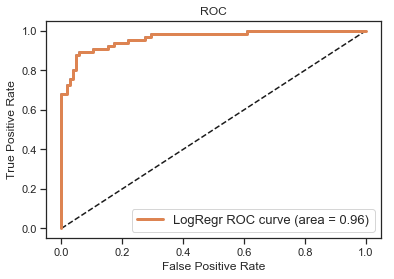

In [56]:
#ROC Curve with AUC
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

#Predictor_score
y_pred_prob1 = log_reg.predict_proba(test_X)[:,1]
print(y_pred_prob1[0:5])


# ROC curve
fpr, tpr, thresholds = roc_curve(test_Y, y_pred_prob1)
#print(fpr)
#print(tpr)
#print(thresholds)
roc_auc_lr = auc(fpr, tpr)
print("Area under curve %s" %roc_auc_lr)

# Plot ROC curve
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr, tpr)  # X axis false +ve rate, Y axis True +ve rate

# Or with AUC
plt.plot(fpr, tpr, lw=3, label='LogRegr ROC curve (area = {:0.2f})'.format(roc_auc_lr))

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=13)
plt.title('ROC')
plt.show()


# WAY 2 : GRID SEARCH

#### BY USING Grid search to select hyper parameter for Logistic Regression
#### Feature selection can be done using Principal Component Analysis done in 3rd way below

In [57]:
# Using GridSearchCV in Logistic regression
from sklearn.model_selection import GridSearchCV

param_grid = {'penalty' : ['l2','l1'],
            'C' : [0.001, 0.01, 0.1, 1, 10, 100, 1000]
             }
#Assign Logistic regression without parameter
log_clf = LogisticRegression(random_state = 42)
#Here scoring is 'accuracy' we can try another similar grid search wth scoring as 'recall'
CV_log_clf = GridSearchCV(estimator = log_clf, param_grid = param_grid , scoring = 'accuracy', verbose = 1, n_jobs = -1)
CV_log_clf.fit(train_X, train_Y)
best_parameters = CV_log_clf.best_params_
print(best_parameters)

random_state = 42
# Fit the logistic regression with best parameter
log_clf = LogisticRegression(C = best_parameters['C'], penalty = best_parameters['penalty'],random_state = random_state)

log_clf.fit(train_X, train_Y)
#Y_pred
y_pred = log_clf.predict(test_X)

#Predictor_score
y_pred_prob = log_clf.predict_proba(test_X)[:,1]
print(y_pred_prob[0:5])


C:\Users\prabh\Anaconda3\lib\site-packages\sklearn\model_selection\_split.py:2053: FutureWarning: You should specify a value for 'cv' instead of relying on the default value. The default value will change from 3 to 5 in version 0.22.
  warnings.warn(CV_WARNING, FutureWarning)
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


Fitting 3 folds for each of 14 candidates, totalling 42 fits
{'C': 10, 'penalty': 'l1'}
[0.00211598 0.05683575 0.9999853  0.97554102 0.00250991]


[Parallel(n_jobs=-1)]: Done  42 out of  42 | elapsed:    4.5s finished
C:\Users\prabh\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)
C:\Users\prabh\Anaconda3\lib\site-packages\sklearn\svm\base.py:922: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  "the number of iterations.", ConvergenceWarning)
C:\Users\prabh\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)
C:\Users\prabh\Anaconda3\lib\site-packages\sklearn\svm\base.py:922: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  "the number of iterations.", ConvergenceWarning)


### 4.1. Model Evaluation -Accuracy Score

In [58]:
metrics.accuracy_score(test_Y, y_pred)
# Prev method had 90% accuracy with this Grid seach approach has 93%

0.9181286549707602

### 4.2. Model Evaluation -Confusion Matrix

In [59]:
# Confusion maxtrix & metrics

cm = confusion_matrix(test_Y, y_pred)
class_names = [0,1]
plt.figure()
print('Confusion matrix : \n',cm)
plt.show()


Confusion matrix : 
 [[101   4]
 [ 10  56]]


<Figure size 432x288 with 0 Axes>

### 4.3. Model Evaluation - classification_report  

In [60]:
# Classification Report

print(classification_report(test_Y, y_pred, target_names= ["Belignant","Malignant"]))
#we can rename 0,1 row name in classification report by target_name
## Compared to Prev method  this Grid seach approach has good precion, recall and F1 score

              precision    recall  f1-score   support

   Belignant       0.91      0.96      0.94       105
   Malignant       0.93      0.85      0.89        66

   micro avg       0.92      0.92      0.92       171
   macro avg       0.92      0.91      0.91       171
weighted avg       0.92      0.92      0.92       171



In [61]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print('Accuracy: {:.2f}'.format(accuracy_score(test_Y, y_pred)))
# Output is not numeric . so throwing error
print('Precision: {:.2f}'.format(precision_score(test_Y, y_pred)))
print('Recall: {:.2f}'.format(recall_score(test_Y, y_pred)))
print('F1: {:.2f}'.format(f1_score(test_Y, y_pred)))
## Compared to Prev method  this Grid seach approach has good precion, recall and F1 score

Accuracy: 0.92
Precision: 0.93
Recall: 0.85
F1: 0.89


### 4.4. Model Evaluation - ROC AUC  

Area under curve 0.9784992784992785


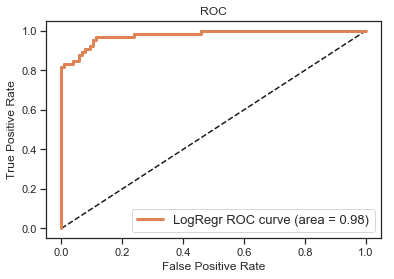

In [62]:
#ROC Curve with AUC
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
# ROC curve
fpr, tpr, thresholds = roc_curve(test_Y, y_pred_prob)
#print(fpr)
#print(tpr)
#print(thresholds)
roc_auc_lr = auc(fpr, tpr)
print("Area under curve %s" %roc_auc_lr)

# Plot ROC curve
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr, tpr)  # X axis false +ve rate, Y axis True +ve rate

# Or with AUC
plt.plot(fpr, tpr, lw=3, label='LogRegr ROC curve (area = {:0.2f})'.format(roc_auc_lr))

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=13)
plt.title('ROC')
plt.show()
## Compared to Prev method  this Grid seach approach has little less AUC

In [181]:
#https://github.com/ranjbanu/Breast-Cancer-Analysis/blob/main/Breast%20cancer%20detection.ipynb
# watch this program, network was slow , so could not watch

# WAY 3 : GRID SEARCH

### Using Principal Component Analysis 

* Lets use  PCA to find the first two principal components, and visualize the data in this new, two-dimensional space, with a single scatter-plot

In [73]:
data.head()
X = data.iloc[:,1:]
Y = data.iloc[:,0]
X.head(),Y.head()

(   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
 0        17.99         10.38          122.80     1001.0          0.11840   
 1        20.57         17.77          132.90     1326.0          0.08474   
 2        19.69         21.25          130.00     1203.0          0.10960   
 3        11.42         20.38           77.58      386.1          0.14250   
 4        20.29         14.34          135.10     1297.0          0.10030   
 
    compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
 0           0.27760          0.3001              0.14710         0.2419   
 1           0.07864          0.0869              0.07017         0.1812   
 2           0.15990          0.1974              0.12790         0.2069   
 3           0.28390          0.2414              0.10520         0.2597   
 4           0.13280          0.1980              0.10430         0.1809   
 
    fractal_dimension_mean           ...             radius_worst  \
 0       

## 3. 1 StandardScaler
- Before apply PCA function better to apply  scaler on data

- Scale data so that each feature has a single unit variance. Without splitting data as test and train

- Generally scale will be applied on Input dataset

In [93]:
from sklearn.preprocessing import StandardScaler

## Here data not splitted, directly applied SCalar and PCA

scaler = StandardScaler()
scaler.fit(X)
#transform 
scaled_data = scaler.transform(X)


## 3. 2 Apply PCA

In [94]:
from sklearn.decomposition import PCA
#To get 99% variance we need to keep (n_components=2)
pca_model = PCA(n_components=2)  
# or
#pca_model = PCA(.95)  
pca_model.fit(scaled_data)
data_2d = pca_model.transform(scaled_data)   

data_df_2d = pd.DataFrame(data_2d)
print("\n" , data_df_2d.head())

#Apply col name
data_df_2d.columns =["PC1","PC2"]
print("\n" , data_df_2d.head())

# variance it provides varience in%
a = pca_model.explained_variance_ratio_
a.sum()


           0          1
0  9.192837   1.948583
1  2.387802  -3.768172
2  5.733896  -1.075174
3  7.122953  10.275589
4  3.935302  -1.948072

         PC1        PC2
0  9.192837   1.948583
1  2.387802  -3.768172
2  5.733896  -1.075174
3  7.122953  10.275589
4  3.935302  -1.948072


0.6324320765155945

In [96]:
print(scaled_data.shape)
print(data_df_2d.shape)
# Here no of rows are same, col reduced to 2

(569, 30)
(569, 2)


** Q1. Plot scatter for 2 components. What inference can you draw from this data? **

Text(0, 0.5, 'Second Principal Component')

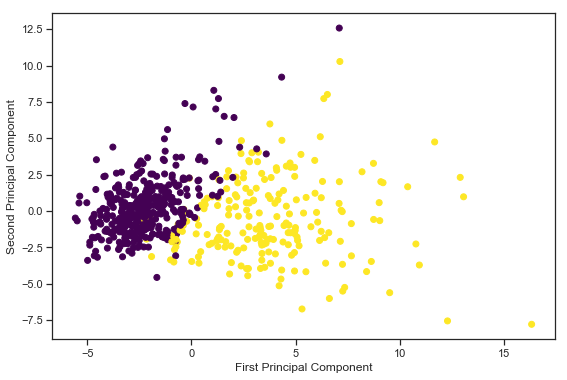

In [97]:
plt.figure(figsize=(9,6))
plt.scatter(data_2d[:,0],data_2d[:,1],c= Y ,cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')

## 3.3 Interpreting the components 

Unfortunately, with this great power of dimensionality reduction, comes the cost of being able to easily understand what these components represent.

The components correspond to combinations of the original features, the components themselves are stored as an attribute of the fitted PCA object:

** Q2. What is the variance attributed by 1st and 2nd Components? **

** Q3 Ideally the sum above should be 100%. What happened to the remaining variance ? **

In [80]:
pca_model.explained_variance_ratio_

array([0.44272026, 0.18971182])

## 3.4 Lets try with 3 Principal Components

In [81]:
pca_3 = PCA(n_components=3)
pca_3.fit(scaled_data)
x_pca_3 = pca_3.transform(scaled_data)

In [82]:
x_pca_3.shape
#Now 3 componets

(569, 3)

* In this numpy matrix array, each row represents a principal component, and each column relates back to the original features. we can visualize this relationship with a heatmap:

** Q4. What is the total variance attributed by three Components? **

In [83]:
pca_3.explained_variance_ratio_

array([0.44272026, 0.18971182, 0.09393163])

## 3.5 Lets check the accuracy for  2 vs. 3 components 

- By splitting data and aftr that apply scalar and PCA which applied before on splitted data

### 3.5.1 Score for 2 component

In [122]:
from sklearn.model_selection import train_test_split

train_data, test_data, train_output, test_output = train_test_split( X, Y, test_size=0.3, random_state=101)

In [116]:
#Apply scalar on train_x and test_x

train_data = scaler.transform(train_data)
test_data = scaler.transform(test_data)

In [117]:
#Aplly PCA component=2 on train_x and test_x

train_data = pca_model.transform(train_data)
test_data = pca_model.transform(test_data)

In [118]:
#LR model on componet 2 applied data
from sklearn.linear_model import LogisticRegression

logisticRegr = LogisticRegression(solver = 'lbfgs')
logisticRegr.fit(train_data, train_output)
pred_y2 = logisticRegr.predict(test_data)

logisticRegr.score(test_data, test_output)

0.9532163742690059

In [119]:
# accuracy_score
metrics.accuracy_score(test_output, pred_y2)

0.9532163742690059

### 3.5.2 Score for 3 components

In [120]:
train_data, test_data, train_output, test_output = train_test_split( X, Y, test_size=0.3, random_state=101)

#Scalar
train_data = scaler.transform(train_data)
test_data = scaler.transform(test_data)

#PCA
train_data = pca_3.transform(train_data)
test_data = pca_3.transform(test_data)

#lOG Regression
logisticRegr = LogisticRegression(solver = 'lbfgs')
logisticRegr.fit(train_data, train_output)
pred_y3 = logisticRegr.predict(test_data)


logisticRegr.score(test_data, test_output)

0.9415204678362573

In [112]:
# accuracy_score
metrics.accuracy_score(test_output, pred_y2)

0.9415204678362573

In [121]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print('Accuracy: {:.2f}'.format(accuracy_score(test_output, pred_y3)))
# Output is not numeric . so throwing error
print('Precision: {:.2f}'.format(precision_score(test_output, pred_y3)))
print('Recall: {:.2f}'.format(recall_score(test_output, pred_y3)))
print('F1: {:.2f}'.format(f1_score(test_output, pred_y3)))

Accuracy: 0.94
Precision: 0.95
Recall: 0.89
F1: 0.92


## 3. 6 Conclusion: Based on these approach
    - Direct LR gives 90
    - But after using PCA, which reduces complexity of the code.
        - Component 2 will give 95.32%
        - Component 2 will give 94.15%
    
        - So Component 2 is the best model, whicch is not lot more accuracy compared to direct LR
        - But performance improved by reducing dimension